# Triplet dissimilarity: perimeter TORP across three financial series

$D(v_1, v_2, v_3) = d(v_1, v_2) + d(v_1, v_3) + d(v_2, v_3)$ with $d$ Euclidean, evaluated as
$T_{ijk} = D(x_i, y_j, z_k)$ for states $x, y, z$ of three different series. The time-aligned diagonal
$T_{ttt}$ measures how far apart the three systems are at the same moment; all other entries compare
different times and act as the reference.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.embedding import embed, average_mutual_information, first_local_minimum, false_nearest_fraction
from recplay.torp import cross_distances, perimeter_tensor, threshold_tensor_by_rate

PRICES = Path("../../data/raw/yahoo/triplet_prices_2015_2024.csv")
OUT = Path("../tables/torp_triplets")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

M, TAU = 3, 1          # common embedding for all three series, so their states share one space
W = 250                # one trading year per window; T has (W - (M - 1) * TAU)^3 entries
RR = 0.05              # fixed recurrence rate over all entries of T

TRIPLETS = {
    "none":            ("TIP", "UNG", "XLP"),
    "mid +":           ("FXY", "GLD", "TIP"),
    "mid + (risk)":    ("EWZ", "FXI", "HYG"),
    "high +":          ("EFA", "IWM", "SPY"),
    "one-out +":       ("GLD", "SLV", "UNG"),
    "mid mixed-sign":  ("XLE", "XLP", "^VIX"),
    "high mixed-sign": ("IWM", "SPY", "^VIX"),
    "one-out −":       ("EFA", "UNG", "^VIX"),
}
TICKERS = sorted({t for tr in TRIPLETS.values() for t in tr} | {"SPY"})

## 2. Data

In [2]:
if PRICES.exists():
    prices = pd.read_csv(PRICES, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    prices = yf.download(TICKERS, start="2015-01-01", end="2025-01-01", auto_adjust=True, progress=False)["Close"]
    prices = prices[prices["SPY"].notna()].ffill(limit=3)
    PRICES.parent.mkdir(parents=True, exist_ok=True)
    prices.to_csv(PRICES)
returns = np.log(prices[TICKERS]).diff().iloc[1:].dropna()
starts = list(range(0, len(returns) - W + 1, W))
print(f"{len(returns)} daily log returns, {returns.index[0].date()} to {returns.index[-1].date()}; {len(starts)} windows of {W}")

def pair_corr(frame, tr):
    c = frame[list(tr)].corr().to_numpy()
    return c[0, 1], c[0, 2], c[1, 2]

pd.DataFrame({name: pair_corr(returns, tr) for name, tr in TRIPLETS.items()}, index=["r_ab", "r_ac", "r_bc"]).T.round(2)

2515 daily log returns, 2015-01-05 to 2024-12-31; 10 windows of 250


,r_ab,r_ac,r_bc
none,0.02,0.02,0.06
mid +,0.45,0.36,0.41
mid + (risk),0.45,0.53,0.46
high +,0.80,0.86,0.87
one-out +,0.78,0.01,0.02
mid mixed-sign,0.42,-0.45,-0.50
high mixed-sign,0.87,-0.65,-0.73
one-out −,0.08,-0.66,-0.06


## 3. Construction check

In [3]:
rng = np.random.default_rng(0)
a, b, c = (rng.standard_normal((40, M)) for _ in range(3))
T = perimeter_tensor(a, b, c, dtype=np.float64)
for i, j, k in [(3, 17, 29), (0, 0, 0), (39, 5, 5)]:
    direct = np.linalg.norm(a[i] - b[j]) + np.linalg.norm(a[i] - c[k]) + np.linalg.norm(b[j] - c[k])
    assert np.isclose(T[i, j, k], direct)
S = perimeter_tensor(a, a, a, dtype=np.float64)
r = np.arange(40)
assert np.allclose(S[r, r], 2 * cross_distances(a, a))      # D(v_i, v_i, v_k) = 2 d(v_i, v_k)
assert np.allclose(S[r, r, r], 0)                          # D(v_i, v_i, v_i) = 0
print("perimeter tensor matches the definition; single-series repeated-index rules hold")

perimeter tensor matches the definition; single-series repeated-index rules hold


## 4. Embedding diagnostics

In [4]:
diag = []
for t in TICKERS:
    x = returns[t].to_numpy()
    ami = average_mutual_information(x, max_lag=10)
    fnn = false_nearest_fraction(x[:1000], tau=TAU, max_m=6)
    diag.append({"ticker": t, "AMI first minimum": first_local_minimum(ami), "AMI lag 1 / lag 0": ami[1] / ami[0],
                 **{f"FNN m={m}": f for m, f in enumerate(fnn, start=1)}})
embedding_diag = pd.DataFrame(diag).set_index("ticker")
embedding_diag.to_csv(OUT / "embedding_diagnostics.csv")
embedding_diag.round(3)

,AMI first minimum,AMI lag 1 / lag 0,FNN m=1,FNN m=2,FNN m=3,FNN m=4,FNN m=5,FNN m=6
ticker,,,,,,,,
EFA,1,0.023,0.967,0.518,0.198,0.155,0.173,0.209
EWZ,1,0.018,0.972,0.540,0.160,0.162,0.187,0.225
FXI,2,0.020,0.970,0.510,0.212,0.185,0.187,0.207
FXY,2,0.022,0.959,0.511,0.190,0.157,0.177,0.223
GLD,1,0.017,0.970,0.496,0.176,0.148,0.188,0.208
HYG,3,0.035,0.976,0.517,0.198,0.149,0.161,0.197
IWM,1,0.022,0.972,0.529,0.179,0.154,0.169,0.204
SLV,1,0.016,0.942,0.508,0.202,0.173,0.200,0.209
SPY,1,0.029,0.958,0.528,0.197,0.148,0.172,0.218


## 5. Triplet tensors per window

In [5]:
def states_of(window, sign=(1, 1, 1)):
    z = window * np.asarray(sign, float)
    z = (z - z.mean(0)) / z.std(0)
    return [embed(z[:, q], M, TAU) for q in range(3)]

variants = [(name, tr, (1, 1, 1), "original") for name, tr in TRIPLETS.items()]
variants += [(name, tr, tuple(-1 if s == "^VIX" else 1 for s in tr), "−VIX") for name, tr in TRIPLETS.items() if "^VIX" in tr]

rows, examples = [], {}
for name, tr, sign, variant in variants:
    for w_id, s0 in enumerate(starts):
        window = returns[list(tr)].iloc[s0:s0 + W]
        st = states_of(window.to_numpy(), sign)
        n = len(st[0])
        idx = np.arange(n)
        T = perimeter_tensor(*st)
        R, eps = threshold_tensor_by_rate(T, RR)
        D_sync = float(T[idx, idx, idx].mean(dtype=np.float64))
        D_all = float(T.mean(dtype=np.float64))
        r = np.array(pair_corr(window * np.asarray(sign, float), tr))
        pair_ratio = []
        for p, q in ((0, 1), (0, 2), (1, 2)):
            d = cross_distances(st[p], st[q])
            pair_ratio.append(np.diag(d).mean() / d.mean())
        rows.append({"category": name, "variant": variant, "a": tr[0], "b": tr[1], "c": tr[2], "window": w_id,
                     "start": window.index[0].date(), "end": window.index[-1].date(), "n_states": n,
                     "r_ab": r[0], "r_ac": r[1], "r_bc": r[2], "mean_r": r.mean(),
                     "D_sync": D_sync, "D_all": D_all, "sync_ratio": D_sync / D_all,
                     "predicted_ratio": float(np.mean(np.sqrt(1 - r))),
                     "pair_ratio_ab": pair_ratio[0], "pair_ratio_ac": pair_ratio[1], "pair_ratio_bc": pair_ratio[2],
                     "eps": eps, "RR_sync": float(R[idx, idx, idx].mean()), "sync_enrichment": float(R[idx, idx, idx].mean()) / RR})
        if w_id == len(starts) - 1:
            examples[(name, variant)] = {"diag": T[idx, idx, idx] / D_all, "plane": R[idx, idx, :], "end": window.index[-1].date()}
        del T, R
cases = pd.DataFrame(rows)
cases.to_csv(OUT / "triplet_torp_windows.csv", index=False)
print(f"{len(cases)} triplet windows")

110 triplet windows


## 6. Summary

In [6]:
summary = (cases.groupby(["category", "variant"], sort=False)
           .agg(mean_r=("mean_r", "mean"), sync_ratio=("sync_ratio", "mean"), sync_ratio_min=("sync_ratio", "min"),
                sync_ratio_max=("sync_ratio", "max"), predicted_ratio=("predicted_ratio", "mean"),
                sync_enrichment=("sync_enrichment", "mean"), D_sync=("D_sync", "mean"), D_all=("D_all", "mean"))
           .reset_index())
summary.to_csv(OUT / "triplet_torp_summary.csv", index=False)
rho_pred = spearmanr(cases["predicted_ratio"], cases["sync_ratio"]).statistic
rho_r = spearmanr(cases["mean_r"], cases["sync_ratio"]).statistic
abs_err = (cases["sync_ratio"] - cases["predicted_ratio"]).abs()
print(f"Spearman(sync_ratio, predicted from correlations) = {rho_pred:.3f}; Spearman(sync_ratio, mean r) = {rho_r:.3f}")
print(f"|sync_ratio - predicted|: median {abs_err.median():.3f}, max {abs_err.max():.3f}")
summary.round(3)

Spearman(sync_ratio, predicted from correlations) = 0.991; Spearman(sync_ratio, mean r) = -0.980
|sync_ratio - predicted|: median 0.012, max 0.087


,category,variant,mean_r,sync_ratio,sync_ratio_min,sync_ratio_max,predicted_ratio,sync_enrichment,D_sync,D_all
0,none,original,0.032,0.973,0.911,1.017,0.983,1.306,6.359,6.534
1,mid +,original,0.445,0.718,0.550,0.800,0.738,5.202,4.694,6.548
2,mid + (risk),original,0.463,0.713,0.556,0.784,0.726,4.694,4.635,6.486
3,high +,original,0.804,0.434,0.311,0.555,0.432,12.774,2.829,6.498
4,one-out +,original,0.274,0.810,0.771,0.858,0.814,3.694,5.337,6.588
5,mid mixed-sign,original,-0.210,1.057,1.006,1.087,1.081,1.105,6.865,6.493
6,high mixed-sign,original,-0.214,0.980,0.931,1.021,1.007,2.427,6.334,6.458
7,one-out −,original,-0.235,1.087,1.070,1.108,1.101,0.831,7.045,6.478
8,mid mixed-sign,−VIX,0.428,0.749,0.594,0.881,0.748,3.694,4.867,6.485
9,high mixed-sign,−VIX,0.780,0.460,0.372,0.551,0.459,11.790,2.963,6.447


## 7. Figures

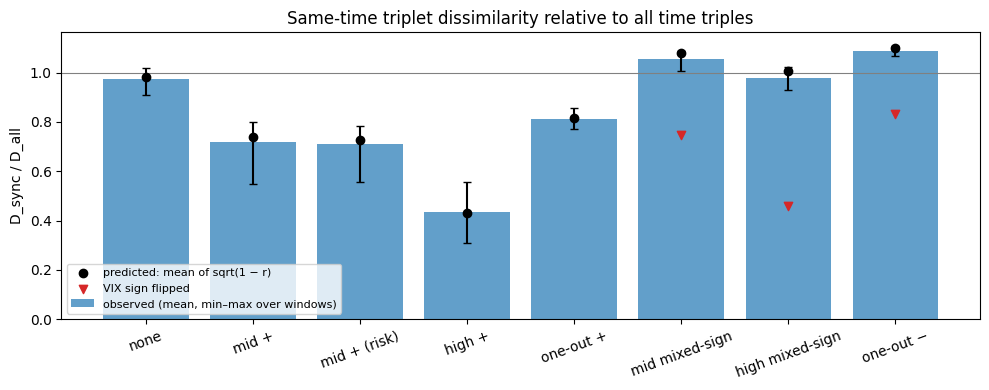

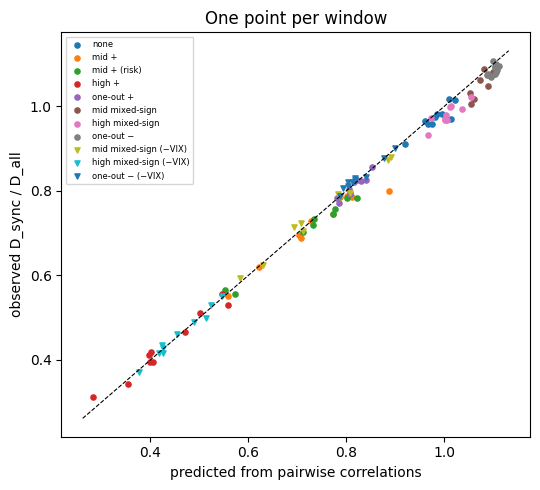

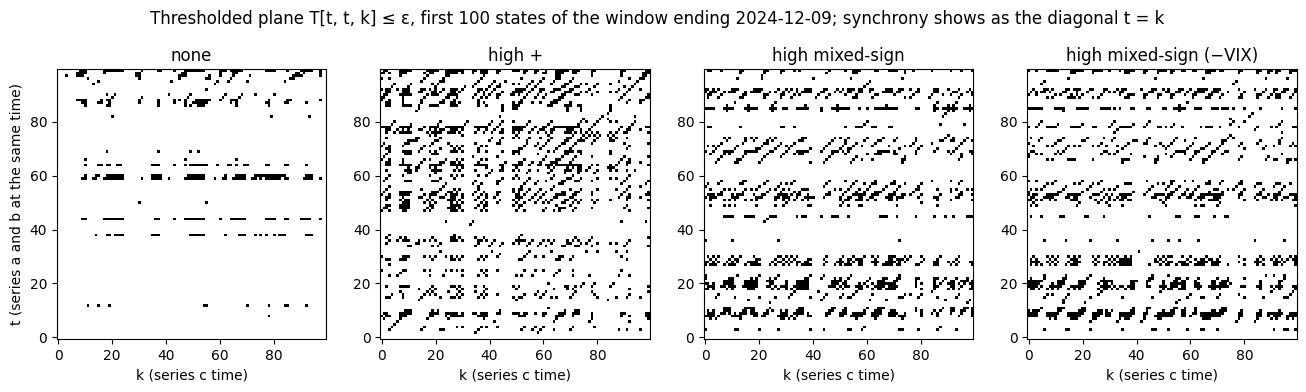

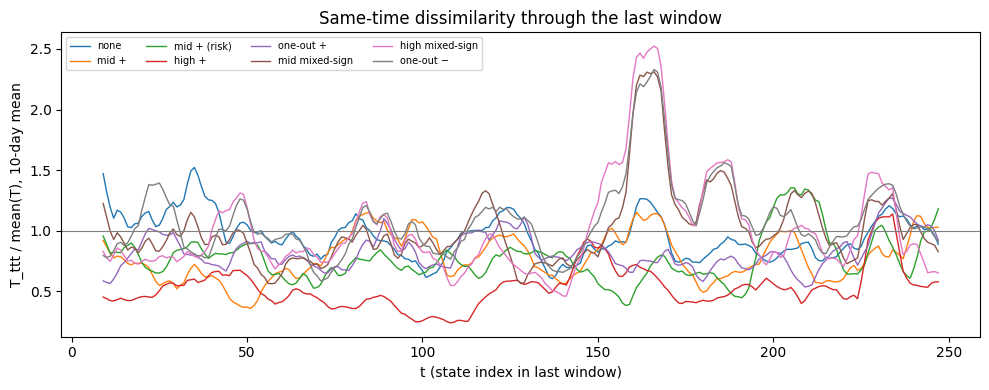

In [7]:
orig = summary[summary.variant == "original"]
flip = summary[summary.variant == "−VIX"]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(orig))
ax.bar(x, orig.sync_ratio, yerr=[orig.sync_ratio - orig.sync_ratio_min, orig.sync_ratio_max - orig.sync_ratio],
       color="C0", alpha=0.7, capsize=3, label="observed (mean, min–max over windows)")
ax.scatter(x, orig.predicted_ratio, color="k", zorder=3, label="predicted: mean of sqrt(1 − r)")
for _, row in flip.iterrows():
    xi = list(orig.category).index(row.category)
    ax.scatter(xi, row.sync_ratio, marker="v", color="C3", zorder=3, label="VIX sign flipped" if xi == list(orig.category).index(flip.category.iloc[0]) else None)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xticks(x, orig.category, rotation=20)
ax.set_ylabel("D_sync / D_all")
ax.set_title("Same-time triplet dissimilarity relative to all time triples")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "sync_ratio_by_category.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, variant), g in cases.groupby(["category", "variant"], sort=False):
    ax.scatter(g.predicted_ratio, g.sync_ratio, s=14, marker="o" if variant == "original" else "v", label=f"{name}{'' if variant == 'original' else ' (−VIX)'}")
lim = [cases[["predicted_ratio", "sync_ratio"]].min().min() - 0.02, cases[["predicted_ratio", "sync_ratio"]].max().max() + 0.02]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="predicted from pairwise correlations", ylabel="observed D_sync / D_all", title="One point per window")
ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "sync_ratio_vs_prediction.png", dpi=150); plt.show()

show = [("none", "original"), ("high +", "original"), ("high mixed-sign", "original"), ("high mixed-sign", "−VIX")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, key in zip(axes, show):
    ax.imshow(examples[key]["plane"][:100, :100], origin="lower", cmap="Greys", interpolation="nearest")
    ax.set(title=f"{key[0]}{'' if key[1] == 'original' else ' (−VIX)'}", xlabel="k (series c time)")
axes[0].set_ylabel("t (series a and b at the same time)")
fig.suptitle(f"Thresholded plane T[t, t, k] ≤ ε, first 100 states of the window ending {examples[show[0]]['end']}; synchrony shows as the diagonal t = k")
plt.savefig(FIG / "torp_plane_examples.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for name in TRIPLETS:
    ax.plot(pd.Series(examples[(name, "original")]["diag"]).rolling(10).mean().to_numpy(), label=name, lw=1)
ax.axhline(1, color="grey", lw=0.8)
ax.set(xlabel="t (state index in last window)", ylabel="T_ttt / mean(T), 10-day mean", title="Same-time dissimilarity through the last window")
ax.legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.savefig(FIG / "sync_dissimilarity_last_window.png", dpi=150); plt.show()

## 8. Findings

Daily log returns 2015–2024, 10 non-overlapping windows of 250 days, each series z-scored per window, m = 3, τ = 1 (AMI's first minimum is lag 1 for 11 of 14 series; FNN is lowest at m = 4, about 0.15, and never reaches zero, as expected for near-random returns). RR = 5 % over all entries of T.

1. **The same-time triplet dissimilarity is a function of the three pairwise correlations.** $D_{sync}/D_{all}$ (mean of $T_{ttt}$ over the mean of all $T_{ijk}$) matches the Gaussian prediction $\tfrac13\sum\sqrt{1-r}$: Spearman 0.991 over 110 windows, median absolute error 0.012 (max 0.087). Mean ratio: none 0.97, mid 0.71–0.72, high 0.43, one-out + 0.81.
2. **Euclidean distance reads anti-correlation as dissimilarity.** The negative triplets score above 1: mid mixed-sign 1.06, one-out − 1.09. Flipping the sign of VIX turns them into their positive counterparts (0.75, 0.83), and high mixed-sign becomes like high + (0.46 vs 0.43).
3. **On the mean, high mixed-sign looks like no correlation** (0.98 vs 0.97): the close IWM–SPY pair cancels the two far pairs with VIX. The thresholded tensor still separates them: the same-time recurrence rate is 2.4× the base rate for high mixed-sign and 1.3× for none (high + 12.8×, one-out − 0.83×).
4. **The uncorrelated triplet is slightly more recurrent at the same time than chance** (1.3×; ratio 0.91–1.02 over windows). The thresholded planes show this mass in horizontal bands of quiet days, so it is likely shared calm and turbulent periods rather than linear co-movement [inference, not tested].

**Meaning.** With Euclidean d, the perimeter triplet measure adds nothing on time-aligned states beyond the three pairwise correlations, and it cannot tell "moves opposite" from "moves independently with larger spread" except through the tail picked out by the threshold. It is a function of the three cross-distance matrices (`cross_distances`), so any triplet-specific value must come from how a model uses the tensor layout, or from a different d.

**Next.** Swap d for a β-divergence (`perimeter_tensor(..., distance=...)`), test absolute returns for the volatility explanation of point 4, and compare the thresholded TORP against the AND of the three pairwise cross-RPs.